# IE7275 Group Project 1: Data Preparation and Exploratory Data Analysis
**Devansh Nayak, Rishi Hirpara, Venkatashivasai Muppidi**

Dataset: Amazon Reviews 2023, Video Games category (McAuley Lab, UC San Diego). This notebook covers dataset
description, inspection, preprocessing and the exploratory analysis. The same processed files are used by every model in the project.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from recsys.data import load

mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, GRAY, ORANGE = "#2a6fb0", "#8a8f98", "#d9822b"
FIG = Path.cwd().parent / "figures"
FIG.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"eda_{name}.png", dpi=150)
    plt.show()

data = load()
log = data.meta["preprocess_log"]
train, val, test, users, items = data.train, data.val, data.test, data.users, data.items
allx = pd.concat([train, val, test], ignore_index=True)
allx["year"] = pd.to_datetime(allx["timestamp"], unit="ms").dt.year
print(data.meta["dataset"], "| data version", data.data_version)

Amazon Reviews 2023, Video Games (McAuley Lab, UCSD) | data version 4fe78b90381a


## 1. Dataset description

**Source.** Amazon Reviews 2023, McAuley Lab (UCSD), `McAuley-Lab/Amazon-Reviews-2023` on Hugging Face.
**Files used.** `raw/review_categories/Video_Games.jsonl` (2.68 GB, one JSON review per line) and
`raw/meta_categories/meta_Video_Games.jsonl` (0.44 GB, one JSON product record per line).
**Reviews:** `user_id`, `parent_asin` (product), `rating` (1 to 5 stars), `timestamp` (milliseconds), plus review text, title, helpful votes.
**Product metadata:** title, store, categories, features, description, price, images.
We use the interaction (user, item, rating, time) and the product text and attributes. Review text is not used by any model.

In [2]:
funnel = pd.DataFrame({
    "step": ["raw reviews in file", "after removing malformed / missing / invalid rows",
             "after collapsing repeated user-item pairs", "after 5-core filter"],
    "interactions": [log["raw_lines"], log["after_cleaning_rows"], log["after_dedupe_rows"], log["after_kcore_rows"]],
    "users": [None, None, log["after_dedupe_users"], log["after_kcore_users"]],
    "items": [None, None, log["after_dedupe_items"], log["after_kcore_items"]],
})
funnel["removed at this step"] = (funnel["interactions"].shift(1) - funnel["interactions"]).astype("Int64")
funnel

,step,interactions,users,items,removed at this step
0,raw reviews in file,4624615,NaN,NaN,<NA>
1,after removing malformed / missing / invalid rows,4624615,NaN,NaN,0
2,after collapsing repeated user-item pairs,4555500,2766656.0,137249.0,69115
3,after 5-core filter,814586,94762.0,25612.0,3740914


In [3]:
checks = pd.DataFrame({"rows flagged": [log["malformed_json"], log["missing_or_unparseable"], log["rating_out_of_range"], log["timestamp_implausible"]]},
                      index=["malformed JSON lines", "missing user, item, rating or timestamp", "rating outside 1-5", "timestamp outside 1990-2023"])
checks

,rows flagged
malformed JSON lines,0
"missing user, item, rating or timestamp",0
rating outside 1-5,0
timestamp outside 1990-2023,0


In [4]:
print(f"5-core keeps {log['after_kcore_rows'] / log['after_dedupe_rows']:.1%} of interactions, "
      f"{log['after_kcore_users'] / log['after_dedupe_users']:.1%} of users, "
      f"{log['after_kcore_items'] / log['after_dedupe_items']:.1%} of items")
print(f"final: {data.n_users:,} users, {data.n_items:,} items, {len(allx):,} interactions, "
      f"density {len(allx) / (data.n_users * data.n_items):.4%}")

5-core keeps 17.9% of interactions, 3.4% of users, 18.7% of items
final: 94,762 users, 25,612 items, 814,586 interactions, density 0.0336%


## 2. Inspecting the data

In [5]:
types = pd.DataFrame([
    ("user_idx", "int32", "categorical id", "interaction"), ("item_idx", "int32", "categorical id", "interaction"),
    ("rating", "float32", "numerical, ordinal 1-5", "interaction"), ("timestamp", "int64", "numerical, time (ms)", "interaction"),
    ("title / features / description", "text", "free text", "item"), ("store, main_category, categories", "text", "categorical", "item"),
    ("price", "float32", "numerical, skewed", "item"),
], columns=["column", "stored as", "kind", "table"])
types

,column,stored as,kind,table
0,user_idx,int32,categorical id,interaction
1,item_idx,int32,categorical id,interaction
2,rating,float32,"numerical, ordinal 1-5",interaction
3,timestamp,int64,"numerical, time (ms)",interaction
4,title / features / description,text,free text,item
5,"store, main_category, categories",text,categorical,item
6,price,float32,"numerical, skewed",item


In [6]:
missing = pd.DataFrame({
    "missing": [items["price"].isna().sum(), (items["store"] == "").sum(), (items["categories"] == "").sum(),
                (items["description"] == "").sum(), (items["features"] == "").sum(), (items["title"] == "").sum()],
}, index=["price", "store", "categories", "description", "features", "title"])
missing["share of items"] = missing["missing"] / data.n_items
missing["handling"] = ["flag price_missing, scaled value set to 0", "code 0 (unknown)", "code 0 (unknown)",
                       "left empty, text field uses the other parts", "left empty, text field uses the other parts", "left empty"]
print("interaction table: no missing values in user, item, rating or timestamp")
missing

interaction table: no missing values in user, item, rating or timestamp


,missing,share of items,handling
price,8481,0.331134,"flag price_missing, scaled value set to 0"
store,120,0.004685,code 0 (unknown)
categories,869,0.033929,code 0 (unknown)
description,6816,0.266125,"left empty, text field uses the other parts"
features,3305,0.129041,"left empty, text field uses the other parts"
title,1,0.000039,left empty


In [7]:
print(items["main_category"].replace("", "(blank)").value_counts().head(6).to_string())
print()
print("rating summary (train):"); print(train["rating"].describe().round(3).to_string())

main_category
Video Games                  17930
Computers                     3263
All Electronics               2645
(blank)                        514
Cell Phones & Accessories      414
Toys & Games                   217

rating summary (train):
count    625062.000
mean          4.281
std           1.167
min           1.000
25%           4.000
50%           5.000
75%           5.000
max           5.000


## 3. Preprocessing and splitting

Steps, in order: parse and drop malformed lines; drop missing or invalid values; keep the earliest interaction of each repeated
user-item pair; iterative 5-core filter; index users and items 0..n-1; leave-one-out temporal split per user
(last interaction = test, second-to-last = validation, the rest = train); item feature encoding.

**Item features.** Price is skewed and 33% missing, so it becomes `price_missing` (flag) and `price_log_z` (log1p, standardised, missing set to 0).
Store, main category and category levels 2 and 3 are integer coded, with code 0 for unknown or rare values.
`text` joins title, features and description for the embedding model. The average rating and rating count stored in the metadata are
excluded on purpose, because they are computed over all reviews including the held-out ones.

**User activity buckets.** Users are split into thirds by their number of training interactions and named as in the proposal: cold (4 or fewer), warm (5 to 6) and heavy (more than 6).
"Cold" here means few interactions, not none. Users with no history are covered by the separate cold-start dataset below.

In [8]:
splits = pd.DataFrame({"interactions": [len(train), len(val), len(test)],
                       "users": [train.user_idx.nunique(), val.user_idx.nunique(), test.user_idx.nunique()],
                       "items": [train.item_idx.nunique(), val.item_idx.nunique(), test.item_idx.nunique()],
                       "earliest": [pd.to_datetime(s.timestamp.min(), unit="ms").date() for s in (train, val, test)],
                       "latest": [pd.to_datetime(s.timestamp.max(), unit="ms").date() for s in (train, val, test)]},
                      index=["train", "validation", "test"])
splits

,interactions,users,items,earliest,latest
train,625062,94762,25527,1999-10-22,2023-08-29
validation,94762,94762,18799,1999-12-15,2023-08-29
test,94762,94762,18219,2000-01-05,2023-09-02


In [9]:
last_train = train.groupby("user_idx")["timestamp"].max().to_numpy()
print("every user: last train time <= val time:", bool((last_train <= val["timestamp"].to_numpy()).all()))
print("every user: val time <= test time:     ", bool((val["timestamp"].to_numpy() <= test["timestamp"].to_numpy()).all()))
print("no user-item pair repeats across splits:", not allx.duplicated(["user_idx", "item_idx"]).any())
print("users whose last two interactions share a timestamp:", log["users_with_tied_last_two_timestamps"])
print("min interactions per user / item:", allx.groupby("user_idx").size().min(), "/", allx.groupby("item_idx").size().min())

every user: last train time <= val time: True
every user: val time <= test time:      True
no user-item pair repeats across splits: True
users whose last two interactions share a timestamp: 4
min interactions per user / item: 5 / 5


### Cold-start dataset
The 5-core filter leaves no user without history, so cold-start users are simulated. A fixed random 10% of users become new users: all of their training interactions
are removed, so no model can learn anything about them. After training, a model is shown only the first 0, 1, 2 or 3 purchases of each new user and must rank their last purchase
among all items except their other purchases. Validation and test files are unchanged, and item popularity is recomputed from the reduced training set.

In [10]:
cold = load(Path.cwd().parent / "data" / "processed_coldstart")
cs = cold.meta["cold_start"]
print(f"{cs['n_new_users']:,} new users ({cs['fraction']:.0%} of users), {cs['removed_train_rows']:,} training rows removed, {len(cold.train):,} train rows left")
print("items with no train interactions:", cs["items_with_no_train_interactions_in_base"], "(main) ->", cs["items_with_no_train_interactions"], "(cold-start)")
print("data versions:", data.data_version, "(main),", cold.data_version, "(cold-start)")

9,476 new users (10% of users), 62,039 training rows removed, 563,023 train rows left
items with no train interactions: 85 (main) -> 114 (cold-start)
data versions: 4fe78b90381a (main), 6943ffc82a19 (cold-start)


## 4. Exploratory data analysis

### 4.1 Rating distribution

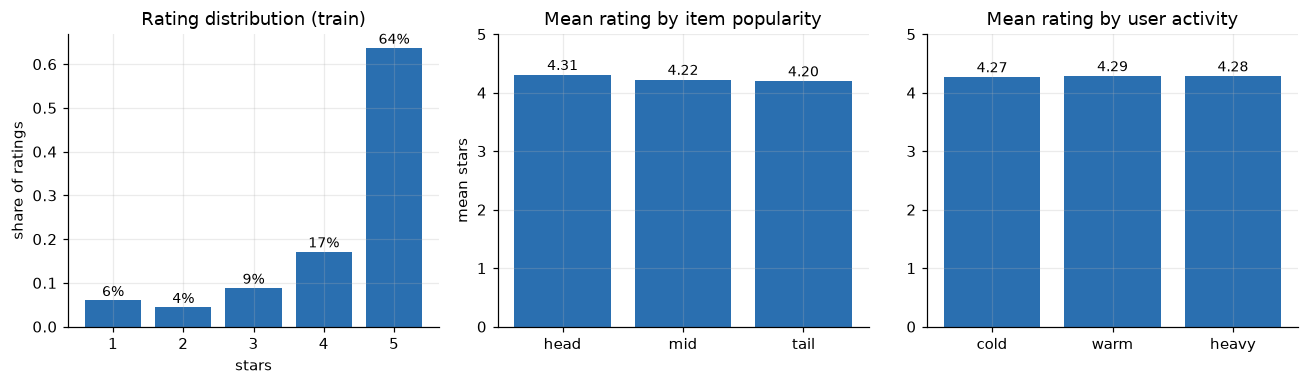

{'head': 4.307, 'mid': 4.225, 'tail': 4.2} {'cold': 4.269999980926514, 'warm': 4.2870001792907715, 'heavy': 4.283999919891357}
global mean rating: 4.281
rating std by split: train 1.167, val 1.226, test 1.292


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
share = train["rating"].value_counts(normalize=True).sort_index()
ax[0].bar(share.index, share.values, color=BLUE)
ax[0].set(title="Rating distribution (train)", xlabel="stars", ylabel="share of ratings")
for x, y in share.items():
    ax[0].text(x, y + 0.01, f"{y:.0%}", ha="center", fontsize=9)

by_item = items.groupby("pop_bin")["item_idx"].apply(lambda s: train[train.item_idx.isin(s)]["rating"].mean())
order = ["head", "mid", "tail"]
ax[1].bar(order, by_item.loc[order].values, color=BLUE)
ax[1].set(title="Mean rating by item popularity", ylabel="mean stars", ylim=(0, 5))
for x, y in zip(order, by_item.loc[order].values):
    ax[1].text(x, y + 0.08, f"{y:.2f}", ha="center", fontsize=9)

by_user = users.set_index("user_idx")["activity_bin"]
ub = train.assign(b=by_user.reindex(train.user_idx).to_numpy()).groupby("b")["rating"].mean().loc[["cold", "warm", "heavy"]]
ax[2].bar(ub.index, ub.values, color=BLUE)
ax[2].set(title="Mean rating by user activity", ylim=(0, 5))
for x, y in zip(ub.index, ub.values):
    ax[2].text(x, y + 0.08, f"{y:.2f}", ha="center", fontsize=9)
save("ratings")
print(by_item.loc[order].round(3).to_dict(), ub.round(3).to_dict())
print("global mean rating:", round(train.rating.mean(), 3))
print("rating std by split: train %.3f, val %.3f, test %.3f" % (train.rating.std(), val.rating.std(), test.rating.std()))

### 4.2 Interactions per user and per item

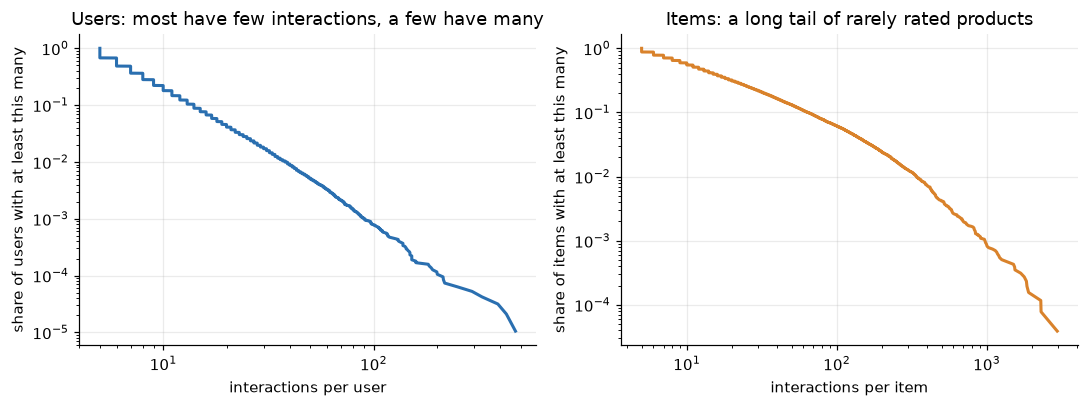

user: min 5, median 6, mean 8.6, 90th pct 14, 99th pct 38, max 473
item: min 5, median 12, mean 31.8, 90th pct 64, 99th pct 341, max 2955


In [12]:
per_user = allx.groupby("user_idx").size()
per_item = allx.groupby("item_idx").size()

def ccdf(ax, s, color, label):
    v = np.sort(s.to_numpy())
    ax.loglog(v, 1 - np.arange(len(v)) / len(v), color=color, lw=2)
    ax.set(xlabel=f"interactions per {label}", ylabel=f"share of {label}s with at least this many")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ccdf(ax[0], per_user, BLUE, "user"); ax[0].set_title("Users: most have few interactions, a few have many")
ccdf(ax[1], per_item, ORANGE, "item"); ax[1].set_title("Items: a long tail of rarely rated products")
save("degree_ccdf")
for name, s in (("user", per_user), ("item", per_item)):
    print(f"{name}: min {s.min()}, median {s.median():.0f}, mean {s.mean():.1f}, 90th pct {s.quantile(.9):.0f}, 99th pct {s.quantile(.99):.0f}, max {s.max()}")

### 4.3 Concentration: popular items and active users

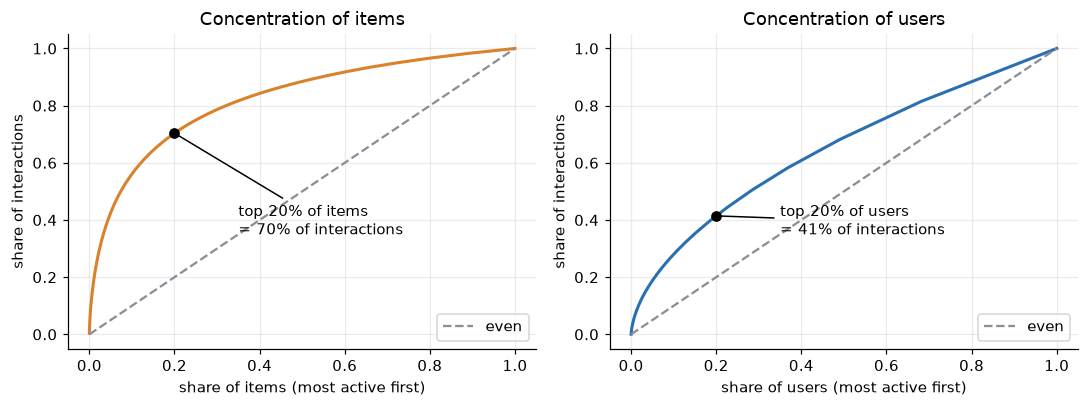

items: top 1% hold 18.6%, top 10% hold 56.1%, top 20% hold 70.4%
users: top 1% hold 7.1%, top 10% hold 28.0%, top 20% hold 41.4%


In [13]:
def lorenz(counts):
    v = np.sort(counts.to_numpy())[::-1]
    return np.arange(1, len(v) + 1) / len(v), np.cumsum(v) / v.sum()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, s, c, label in ((ax[0], per_item, ORANGE, "items"), (ax[1], per_user, BLUE, "users")):
    x, y = lorenz(s)
    a.plot(x, y, color=c, lw=2); a.plot([0, 1], [0, 1], color=GRAY, ls="--", label="even")
    i20 = int(0.2 * len(x)); a.scatter([x[i20]], [y[i20]], color="black", zorder=3)
    a.annotate(f"top 20% of {label}\n= {y[i20]:.0%} of interactions", (x[i20], y[i20]), (0.35, 0.35), arrowprops=dict(arrowstyle="-", color="black"))
    a.set(xlabel=f"share of {label} (most active first)", ylabel="share of interactions", title=f"Concentration of {label}")
    a.legend(loc="lower right")
save("concentration")
for name, s in (("items", per_item), ("users", per_user)):
    v = np.sort(s.to_numpy())[::-1]
    print(f"{name}: top 1% hold {v[:max(1, len(v)//100)].sum() / v.sum():.1%}, top 10% hold {v[:len(v)//10].sum() / v.sum():.1%}, top 20% hold {v[:len(v)//5].sum() / v.sum():.1%}")

In [14]:
top = items.sort_values("n_train", ascending=False).head(10)[["title", "store", "n_train", "item_idx"]].copy()
top["mean rating"] = train.groupby("item_idx")["rating"].mean().reindex(top["item_idx"]).round(2).to_numpy()
top["title"] = top["title"].str.slice(0, 70)
top.drop(columns="item_idx").rename(columns={"n_train": "train interactions"}).reset_index(drop=True)

,title,store,train interactions,mean rating
0,amFilm Tempered Glass Screen Protector for Nin...,amFilm,2062,4.68
1,Skyrim VR - PlayStation 4,Bethesda,1833,4.50
2,Grand Theft Auto V: Premium Edition - Xbox One...,Rockstar Games,1768,4.57
3,PlayStation 4 500GB Console [Old Model][Discon...,PlayStation,1559,4.40
4,Xbox Live Gold: 1 Month Membership [Digital Code],Xbox,1400,4.73
5,Assassin's Creed IV Black Flag - PC,Ubisoft,1298,4.57
6,Battlefield 4 - Playstation 3,Electronic Arts,1276,3.79
7,Fallout 4 - Xbox One,Bethesda,1275,4.33
8,PlayStation Plus: 12 Month Membership [Digital...,PlayStation,1272,4.77
9,DualShock 4 Wireless Controller for PlayStatio...,PlayStation,1175,4.53


### 4.4 The user-item interaction matrix

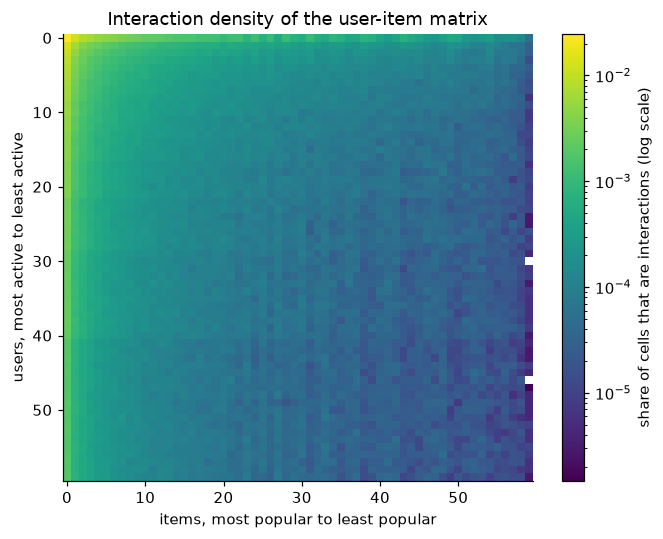

densest cell 2.457%, sparsest nonzero cell 0.00015%, overall 0.0258%


In [15]:
# Rank users and items by activity, cut each axis into 60 equal-count groups, and plot interaction density per cell.
u_rank = (-users["n_train"]).rank(method="first").to_numpy().astype(int) - 1
i_rank = (-items["n_train"]).rank(method="first").to_numpy().astype(int) - 1
nb = 60
ub_, ib_ = u_rank[train.user_idx] * nb // data.n_users, i_rank[train.item_idx] * nb // data.n_items
cell = np.zeros((nb, nb)); np.add.at(cell, (ub_, ib_), 1)
density = cell / ((data.n_users / nb) * (data.n_items / nb))

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(density, norm=LogNorm(vmin=density[density > 0].min(), vmax=density.max()), cmap="viridis", aspect="auto")
ax.set(xlabel="items, most popular to least popular", ylabel="users, most active to least active", title="Interaction density of the user-item matrix")
ax.grid(False); plt.colorbar(im, label="share of cells that are interactions (log scale)")
save("matrix_density")
print(f"densest cell {density.max():.3%}, sparsest nonzero cell {density[density > 0].min():.5%}, overall {len(train) / (data.n_users * data.n_items):.4%}")

White cells contain no interactions. Interactions pile up in the corner where active users meet popular items, and the least popular items are nearly empty.

### 4.5 Time

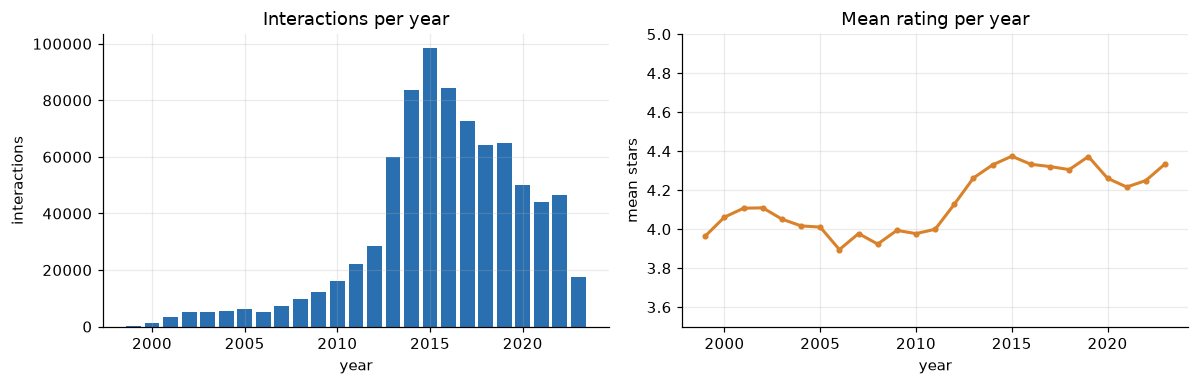

share of interactions from 2015 on: 0.666 | busiest year: 2015 (98,466)


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
yr = allx.groupby("year").size()
ax[0].bar(yr.index, yr.values, color=BLUE); ax[0].set(title="Interactions per year", xlabel="year", ylabel="interactions")
my = allx.groupby("year")["rating"].mean()
ax[1].plot(my.index, my.values, color=ORANGE, lw=2, marker="o", ms=3); ax[1].set(title="Mean rating per year", xlabel="year", ylabel="mean stars", ylim=(3.5, 5))
save("time")
print("share of interactions from 2015 on:", round((allx.year >= 2015).mean(), 3), "| busiest year:", yr.idxmax(), f"({yr.max():,})")

### 4.6 Item attributes

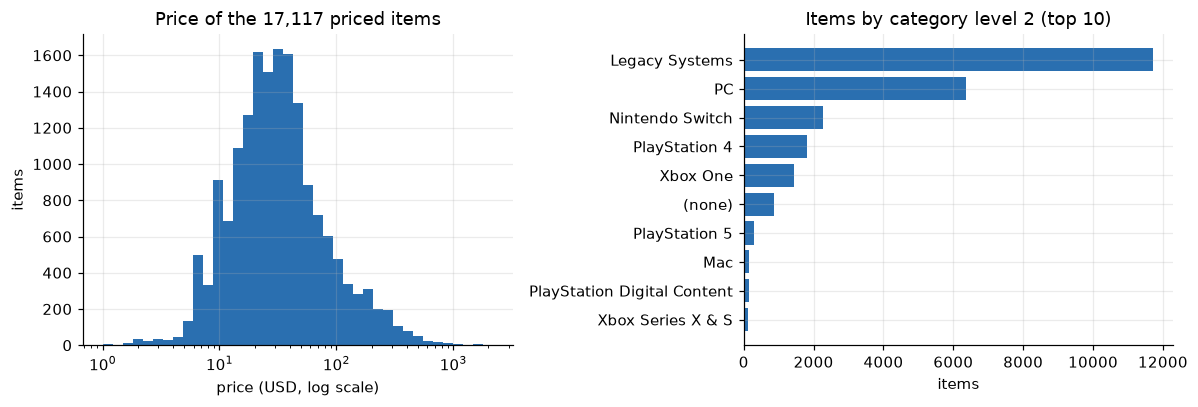

price median / p99 / max: 29.92 397.81 2189.75 | 14 items priced under $1 not plotted
price_log_z after scaling (priced items): mean 0.0 std 1.0


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
p = items["price"].dropna(); below_one = int((p < 1).sum()); p = p[p >= 1]
ax[0].hist(p, bins=np.logspace(np.log10(p.min()), np.log10(p.max()), 40), color=BLUE)
ax[0].set(xscale="log", title=f"Price of the {len(p):,} priced items", xlabel="price (USD, log scale)", ylabel="items")
cat2 = items["categories"].str.split(" > ").str[1].fillna("(none)").value_counts().head(10)[::-1]
ax[1].barh(cat2.index, cat2.values, color=BLUE); ax[1].set(title="Items by category level 2 (top 10)", xlabel="items")
save("attributes")
print("price median / p99 / max:", round(p.median(), 2), round(p.quantile(.99), 2), round(p.max(), 2), f"| {below_one} items priced under $1 not plotted")
print("price_log_z after scaling (priced items): mean", round(items.loc[items.price_missing == 0, "price_log_z"].mean(), 4),
      "std", round(items.loc[items.price_missing == 0, "price_log_z"].std(), 4))

### 4.7 Sequence length, cold items, and what the test set looks like

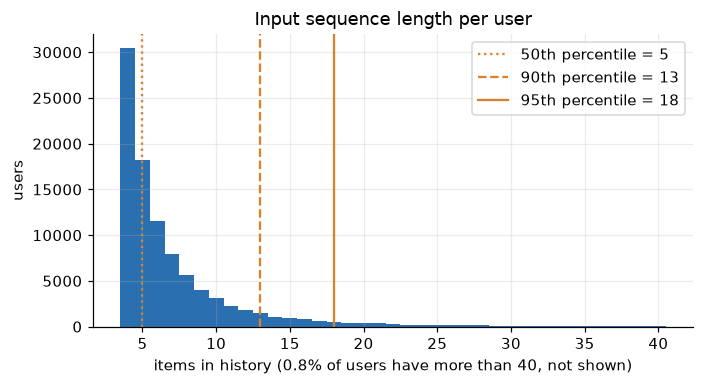

{0.5: 5.0, 0.9: 13.0, 0.95: 18.0, 0.99: 37.0} | max 472


In [18]:
seq = users["n_train"] + 1   # train items plus the validation item = what a sequence model sees at test time
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(seq[seq <= 40], bins=np.arange(3.5, 41.5), color=BLUE)
for q, ls in ((0.5, ":"), (0.9, "--"), (0.95, "-")):
    ax.axvline(seq.quantile(q), color=ORANGE, ls=ls, label=f"{int(q*100)}th percentile = {seq.quantile(q):.0f}")
ax.set(title="Input sequence length per user", xlabel=f"items in history ({(seq > 40).mean():.1%} of users have more than 40, not shown)", ylabel="users"); ax.legend()
save("sequence_length")
print({q: float(seq.quantile(q)) for q in (0.5, 0.9, 0.95, 0.99)}, "| max", int(seq.max()))

In [19]:
test_bin = items["pop_bin"].to_numpy()[test["item_idx"]]
tb = pd.Series(test_bin).value_counts(normalize=True).reindex(["head", "mid", "tail", "cold"])
print("test targets by popularity of the target item:"); print((tb * 100).round(2).astype(str).add("%").to_string())
print()
print("items per bin:", items["pop_bin"].value_counts().reindex(["head", "mid", "tail", "cold"]).to_dict())
print("test targets on items never seen in train:", int((test_bin == "cold").sum()))
print("users per activity bin:", users["activity_bin"].value_counts().to_dict(), "|", data.meta["user_activity_bins"])
pd.crosstab(users["activity_bin"], pd.Series(test_bin, index=users.index, name="target item bin")).loc[["cold", "warm", "heavy"], ["head", "mid", "tail", "cold"]]

test targets by popularity of the target item:
head    63.45%
mid     18.27%
tail    17.91%
cold     0.36%

items per bin: {'head': 5106, 'mid': 7658, 'tail': 12763, 'cold': 85}
test targets on items never seen in train: 345
users per activity bin: {'cold': 48624, 'heavy': 26671, 'warm': 19467} | {'cold': 'n_train <= 4', 'warm': '4 < n_train <= 6', 'heavy': 'n_train > 6'}


target item bin,head,mid,tail,cold
activity_bin,,,,
cold,31383,8725,8350,166
warm,12377,3564,3466,60
heavy,16366,5026,5160,119


## 5. Findings

**1. We model the dense core of Amazon, not the typical shopper.** The 5-core filter keeps 17.9% of interactions, 3.4% of users and 18.7% of items
(4.56M interactions down to 814,586). Results describe users with at least five reviews. The raw file had no malformed rows, missing fields or invalid
values, so cleaning removed only 69,115 repeated user-item pairs.

**2. Ratings carry little signal.** 64% of ratings are five stars (mean 4.28), and the mean barely moves with item popularity (4.31 head, 4.23 mid, 4.20 tail)
or user activity (4.27 to 4.29). Held-out ratings are also more spread out than training ratings (std 1.29 test, 1.23 validation, 1.17 train).
We therefore expect modest gains in rating prediction: predicting the global mean gives test RMSE 1.295 and a shrunk item mean gives 1.250. Ranking metrics are the more informative evaluation.

**3. Popularity dominates, so popularity is a hard baseline.** The top 20% of items hold 70.4% of interactions, and 63.5% of test targets are head items.
A recommender that shows everyone the same list already reaches Recall@10 = 0.0249 against 0.0004 for chance. Beating it requires real personalisation,
which is why we report results by item-popularity slice and add coverage, novelty and Gini.

**4. Activity is skewed but milder than popularity.** The top 10% of users hold 28.0% of interactions. The median user has 6 interactions in total and the maximum is 473
(most active item: 2,955). The matrix is extremely sparse (density 0.034%), with interactions packed where active users meet popular items.

**5. Histories are short.** At test time the median user has 5 items of history, 95% have 18 or fewer and 99% have 37 or fewer. A sequential model only needs a
maximum length of about 20, and it has little context to exploit for most users, so a large advantage over simpler models should not be assumed.

**6. Cold start is small but real.** 85 items (0.3%) have no training interactions and 345 test targets (0.36%) fall on them, while 17.9% of test targets are tail items.
Collaborative models cannot rank cold items. This is where a text-based model can help.

**7. The catalog is broader than games.** 30% of items have a main category other than Video Games (Computers 3,263, All Electronics 2,645, Cell Phones 414, ...), and the most
interacted item is a Nintendo Switch screen protector, alongside Xbox Live and PlayStation Plus memberships and consoles. Items like these may strengthen
the popularity signal.

**8. Time and metadata.** 67% of interactions are from 2015 onward (peak 2015, 98,466) and mean rating rose from about 4.0 in the 2000s to about 4.3. Because the split is per user,
test interactions span 1999 to 2023 rather than one cut-off date. Item metadata is incomplete: price is missing for 33.1% of items, the description is empty for 26.6% and features for 12.9%,
so the text field falls back to whichever parts exist and price carries a missing flag.